# 01 — Causal Discovery for Trading Halts

This notebook builds a reproducible **synthetic event-study dataset**, explores its relationships, encodes the causal assumptions as a DAG, then uses DoWhy to identify and estimate the halt effect on post-event market quality. It does not require MongoDB or proprietary market data.

> Synthetic results validate the workflow only. Correlation patterns do not establish causal direction; the DAG and adjustment set must be justified by domain knowledge. Replace the simulator with properly aligned real market data before interpreting an estimate.

In [1]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from dowhy import CausalModel

# Ensure imports work when Jupyter starts with notebooks/ as its working directory.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)
pd.set_option("display.precision", 4)
print(f"Project root: {PROJECT_ROOT}")

c:\Users\kenne\OpenBB\conda\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: C:\Users\kenne\OneDrive\Desktop\Friction_Modeling\Structural-Friction-Modeling


## 1. Create an event-level dataset

The simulator makes halts more likely during market stress and makes both stress and halts affect the outcome. This creates confounding, so an unadjusted comparison will generally differ from the known causal effect.

In [2]:
n_events = 5_000
macro_stress = rng.normal(size=n_events)
benchmark_return = 0.012 * macro_stress + rng.normal(0, 0.012, n_events)
vix_level = np.clip(20 + 5 * macro_stress + rng.normal(0, 2, n_events), 9, None)

# Treatment assignment depends on stress and market movement (confounding).
halt_probability = 1 / (1 + np.exp(-(-2.0 + 0.9 * macro_stress - 10 * benchmark_return)))
halt = rng.binomial(1, halt_probability)

# Outcome is quoted spread in dollars per share; effect is known by construction.
TRUE_HALT_EFFECT = 0.08
spread = (
    0.04
    + TRUE_HALT_EFFECT * halt
    + 0.025 * macro_stress
    - 0.7 * benchmark_return
    + rng.normal(0, 0.025, n_events)
)

events = pd.DataFrame(
    {
        "treatment_group": halt,
        "effective_spread": spread,
        "macro_stress": macro_stress,
        "benchmark_return": benchmark_return,
        "vix_level": vix_level,
    }
)
events.head()

,treatment_group,effective_spread,macro_stress,benchmark_return,vix_level
0,0,0.0298,0.3047,0.0006,21.8761
1,0,0.0357,-1.0400,-0.0161,16.5983
2,1,0.1355,0.7505,0.0006,20.8077
3,0,0.0661,0.9406,0.0164,24.1322
4,0,-0.0095,-1.9510,-0.0206,11.9031


## 2. Inspect associations and state the causal assumptions

The DAG represents the assumed backdoor paths: pre-event market stress and benchmark movement influence both halt risk and spreads. They should therefore be adjusted for. A causal graph is an explicit modeling choice, not something correlations alone can prove.

Halt prevalence: 0.139


,treatment_group,effective_spread,macro_stress,benchmark_return,vix_level
treatment_group,1.00,0.71,0.24,0.12,0.22
effective_spread,0.71,1.00,0.53,0.20,0.50
macro_stress,0.24,0.53,1.00,0.69,0.93
benchmark_return,0.12,0.20,0.69,1.00,0.64
vix_level,0.22,0.50,0.93,0.64,1.00


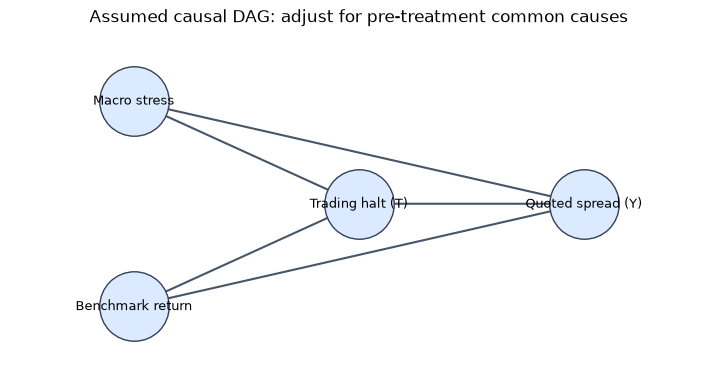

In [8]:
association_cols = [
    "treatment_group",
    "effective_spread",
    "macro_stress",
    "benchmark_return",
    "vix_level",
]
print("Halt prevalence:", events["treatment_group"].mean().round(3))
display(events[association_cols].corr().round(2))

# Render the assumed causal structure; these edges encode domain assumptions.
node_positions = {
    "Macro stress": (-1.0, 0.65),
    "Benchmark return": (-1.0, -0.65),
    "Trading halt (T)": (0.0, 0.0),
    "Quoted spread (Y)": (1.0, 0.0),
}
node_edges = [
    ("Macro stress", "Trading halt (T)"),
    ("Macro stress", "Quoted spread (Y)"),
    ("Benchmark return", "Trading halt (T)"),
    ("Benchmark return", "Quoted spread (Y)"),
    ("Trading halt (T)", "Quoted spread (Y)"),
]
plt.figure(figsize=(9, 4.5))
for source, target in node_edges:
    plt.annotate(
        "",
        xy=node_positions[target],
        xytext=node_positions[source],
        arrowprops={"arrowstyle": "->", "color": "#475569", "lw": 1.5},
    )
for label, position in node_positions.items():
    plt.scatter(*position, s=2_500, color="#dbeafe", edgecolor="#334155", zorder=3)
    plt.text(*position, label, ha="center", va="center", fontsize=9, zorder=4)
plt.title("Assumed causal DAG: adjust for pre-treatment common causes")
plt.xlim(-1.55, 1.55)
plt.ylim(-1.1, 1.1)
plt.axis("off")
causal_figure_path = PROJECT_ROOT / "docs" / "images" / "causal_dag.png"
causal_figure_path.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(causal_figure_path, dpi=160, bbox_inches="tight")
plt.show()

## 3. Estimate the adjusted halt effect

First compare treated and untreated observations without adjustment. Then ask DoWhy to identify the backdoor estimand and estimate it by linear regression with the pre-treatment confounders. The data-generating treatment effect is $0.08$ dollars per share.

In [7]:
naive_ate = (
    events.loc[events["treatment_group"] == 1, "effective_spread"].mean()
    - events.loc[events["treatment_group"] == 0, "effective_spread"].mean()
)

causal_model = CausalModel(
    data=events,
    treatment="treatment_group",
    outcome="effective_spread",
    common_causes=["macro_stress", "benchmark_return"],
)
identified_estimand = causal_model.identify_effect()
causal_estimate = causal_model.estimate_effect(
    identified_estimand,
    method_name="backdoor.linear_regression",
    test_significance=True,
)

print(f"Unadjusted difference: ${naive_ate:.4f} per share")
print(f"DoWhy adjusted ATE:   ${float(causal_estimate.value):.4f} per share")
print(f"Known synthetic ATE:  ${TRUE_HALT_EFFECT:.4f} per share")
print("Identified estimand:")
print(identified_estimand)

Unadjusted difference: $0.0913 per share
DoWhy adjusted ATE:   $0.0777 per share
Known synthetic ATE:  $0.0800 per share
Identified estimand:
Estimand type: EstimandType.NONPARAMETRIC_ATE

### Estimand : 1
Estimand name: backdoor
Estimand expression:
        d                                                            
──────────────────(E[effective_spread|benchmark_return,macro_stress])
d[treatment_group]                                                   
Estimand assumption 1, Unconfoundedness: If U→{treatment_group} and U→effective_spread then P(effective_spread|treatment_group,benchmark_return,macro_stress,U) = P(effective_spread|treatment_group,benchmark_return,macro_stress)

### Estimand : 2
Estimand name: iv
No such variable(s) found!

### Estimand : 3
Estimand name: frontdoor
No such variable(s) found!

### Estimand : 4
Estimand name: general_adjustment
Estimand expression:
        d                                                            
──────────────────(E[effective_spre

## 4. Interpretation and next steps

- Compare the adjusted estimate with the known synthetic effect; sampling error means exact equality is not expected.
- For real estimation, use pre-halt confounders only. Avoid conditioning on variables measured after treatment or derived from outcomes.
- A previous-day control is not automatically exchangeable: account for trading calendars, time of day, overlapping events, and market regimes.
- The current `HaltCausalEngine` defaults to covariates such as realized volatility. Review the causal timing and DAG before using that default set; post-treatment variables can bias an effect estimate.

Next, use the simulation notebook to quantify latent-price uncertainty and liquidity-adjusted tail loss.